# Who is harmed in road-tractor casualty collisions?

## Summary
The following computed summary uses the rebuilt casualty tables and selected official source releases. Complete event records include tractor occupants, people in other vehicles, and vulnerable road users.

Record-resolution scenarios expose uncertain identity and contradictory coded severity. They are **not bounds on true casualties or confidence intervals**. Unknown severity remains unallocated. The target 2016–2025 remains open; available microdata end in 2021. Source-version repairs include annual 2014–2017 releases and the alternate 2019 XLSX; the earlier files and results are preserved.


## Context & Methods
We select complete collision events with `V_TYPE=08` anywhere, then count person keys and unresolved records across **all involved vehicles and pedestrians**. Severity 3 is death; 2 is injury. Dummy person `P_ID=NN` is excluded; pedestrian dummy vehicle 99 is retained.

### Key Assumptions
Known `(source_id,C_YEAR,C_CASE,V_ID,P_ID)` keys represent recorded persons. Conflicting alternatives remain visible. Unidentified rows are not assigned identities. Low scenario = identified keys with certain coded outcome; high = keys with possible coded outcome plus raw unresolved positive-outcome rows. Unknown and not-applicable severity are distinct. Categories partition outcomes, preserving other/unknown and conflicting categories. Motorcyclists, cyclists and pedestrians are separate.

Source metadata and hashes: `data/derived/casualties/source_manifest.json`, `validation.json`; analysis hashes: `reports/casualties/summary.json`. Source code: `src/truck_collisions/build_casualties.py` and `analyze_casualties.py`. Independent aggregate checks below read the person artifacts directly; they do not independently establish the truth of source identities.

In [1]:
from pathlib import Path
import os, sys, csv, json, subprocess, html
root=Path.cwd()
if not (root/'pyproject.toml').exists(): root=root.parent
assert (root/'data/derived/casualties/person_units.parquet').exists()
os.chdir(root)
sys.path.insert(0,str(root/'src'))
os.environ.setdefault('MPLCONFIGDIR','/tmp/collisions-matplotlib')
import duckdb
from IPython.display import display, HTML, Image, Markdown
from truck_collisions.analyze_casualties import read_csv, make_figures
subprocess.run([sys.executable,'-m','truck_collisions.analyze_casualties'],check=True,env={**os.environ,'PYTHONPATH':str(root/'src')},capture_output=True)
data=root/'data/derived/casualties'
out=root/'reports/casualties'
annual=read_csv(out/'annual_counts.csv')
grouped=read_csv(out/'annual_group_counts.csv')
def show_table(rows,columns):
    display(HTML('<table><thead><tr>'+''.join('<th>'+html.escape(c)+'</th>' for c in columns)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+html.escape(str(r[c]))+'</td>' for c in columns)+'</tr>' for r in rows)+'</tbody></table>'))
summary=json.loads((out/'summary.json').read_text())
summary['checks']

{'annual_rows': 46,
 'annual_group_rows': 322,
 'all_group_additivity': 'passed',
 'scenario_ordering': 'passed'}

In [2]:
first=next(r for r in annual if r['year']==2012 and r['subset']=='observed')
last=next(r for r in annual if r['year']==2021 and r['subset']=='observed')
pooled_other=sum(r['deaths_record_scenario_low'] for r in grouped if r['subset']=='observed' and 2012<=r['year']<=2021 and r['road_user_group']=='other_motor_vehicle_occupant')
pooled_all=sum(r['deaths_record_scenario_low'] for r in annual if r['subset']=='observed' and 2012<=r['year']<=2021)
display(Markdown(f"**Rebuilt 2012–2021 results:** deaths {first['deaths_record_scenario_low']:,} → {last['deaths_record_scenario_low']:,} ({100*(last['deaths_record_scenario_low']/first['deaths_record_scenario_low']-1):+.1f}%); nonfatal injuries {first['injuries_record_scenario_low']:,}–{first['injuries_record_scenario_high']:,} → {last['injuries_record_scenario_low']:,}–{last['injuries_record_scenario_high']:,}. Other motor vehicle occupants account for **{pooled_other:,}/{pooled_all:,} = {100*pooled_other/pooled_all:.2f}%** of identified, certain-outcome deaths pooled across this decade."))


**Rebuilt 2012–2021 results:** deaths 233 → 191 (-18.0%); nonfatal injuries 4,337–4,337 → 2,828–2,844. Other motor vehicle occupants account for **1,581/2,206 = 71.67%** of identified, certain-outcome deaths pooled across this decade.

## Data
### Independently check all annual group aggregates
Recompute identified-outcome sums and unresolved raw-row contributions from the person artifacts in SQL. This verifies the analysis tables against their direct inputs, including observed and strict event subsets.

In [3]:
connection=duckdb.connect()
connection.execute(f"CREATE VIEW units AS SELECT * FROM read_parquet('{data}/person_units.parquet')")
connection.execute(f"CREATE VIEW alternatives AS SELECT * FROM read_parquet('{data}/unresolved_and_dummy_records.parquet')")
checked=0
for subset,predicate in [('observed','TRUE'),('strict','is_analysis_candidate')]:
    known={(r[0],r[1]):r[2:] for r in connection.execute(f"SELECT C_YEAR,road_user_group,sum(deaths_min),sum(deaths_max),sum(injuries_min),sum(injuries_max) FROM units WHERE {predicate} GROUP BY C_YEAR,road_user_group").fetchall()}
    unresolved={(r[0],r[1]):r[2:] for r in connection.execute(f"SELECT C_YEAR,road_user_group,sum(CASE WHEN P_ISEV='3' THEN record_multiplicity ELSE 0 END),sum(CASE WHEN P_ISEV='2' THEN record_multiplicity ELSE 0 END) FROM alternatives WHERE identity_status='unresolved_identity' AND {predicate} GROUP BY C_YEAR,road_user_group").fetchall()}
    for row in grouped:
        if row['subset']!=subset:continue
        key=(row['year'],row['road_user_group'])
        dmin,dmax,imin,imax=known.get(key,(0,0,0,0))
        draw,iraw=unresolved.get(key,(0,0))
        assert (row['deaths_record_scenario_low'],row['deaths_record_scenario_high'],row['injuries_record_scenario_low'],row['injuries_record_scenario_high'])==(dmin,dmax+draw,imin,imax+iraw)
        checked+=1
assert checked==322
print(f'{checked} annual group rows independently reconciled to person artifacts.')
quality=json.loads((data/'validation.json').read_text())['quality']
quality

322 annual group rows independently reconciled to person artifacts.


{'input_record_rows': 212532,
 'distinct_normalized_records': 212518,
 'exact_repeated_rows_beyond_first': 14,
 'identified_person_keys': 211699,
 'conflicting_person_keys': 87,
 'conflicting_severity_keys': 43,
 'ambiguous_group_keys': 120,
 'unresolved_identity_rows': 133,
 'dummy_rows': 438,
 'dummy_positive_casualty_rows': 0,
 'tractor_events': 80540,
 'event_rows_mismatch': 0,
 'injury_events_with_fatal_person_keys': 0,
 'invalid_event_severity_person_keys': 0,
 'fatal_events_without_fatal_record': 0}

## Results
### Annual harm and record resolution
Low/high spans reflect the documented record scenarios. Unknown or absent people and unknown severity remain outside the recorded harm totals.

year,deaths_record_scenario_low,deaths_record_scenario_high,injuries_record_scenario_low,injuries_record_scenario_high,unknown_severity_identified_keys,unknown_severity_unresolved_rows
2012,233,233,4337,4337,350,0
2016,217,217,3794,3796,225,6
2019,222,222,3665,3666,82,6
2020,179,181,2599,2625,246,10
2021,191,191,2828,2844,221,4


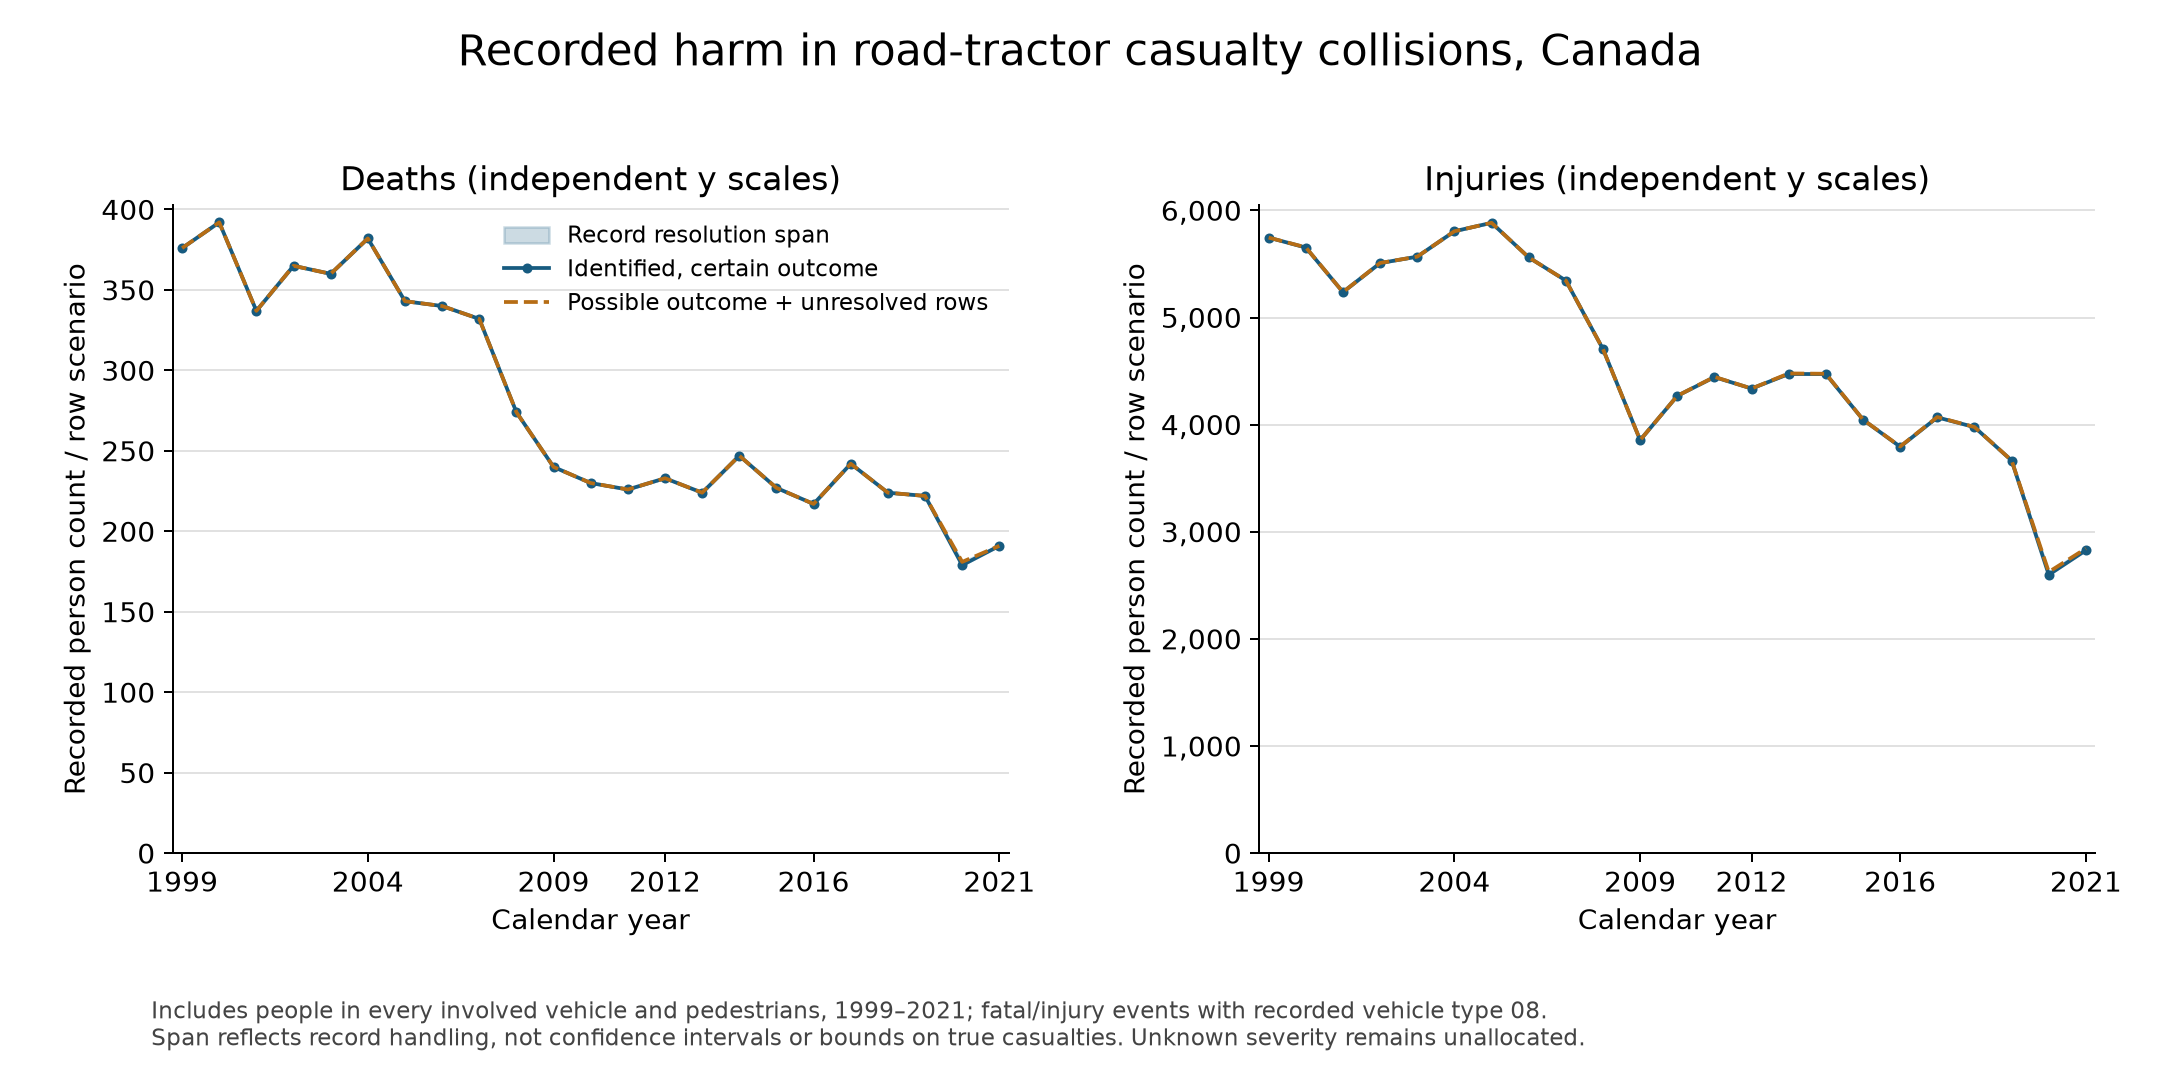

In [4]:
show_table([r for r in annual if r['subset']=='observed' and r['year'] in (2012,2016,2019,2020,2021)],['year','deaths_record_scenario_low','deaths_record_scenario_high','injuries_record_scenario_low','injuries_record_scenario_high','unknown_severity_identified_keys','unknown_severity_unresolved_rows'])
# Editable plotting implementation lives in the analysis module and uses these reviewed rows.
make_figures(out,annual,grouped)
display(Image(filename=str(out/'annual_harm.png')))

Recorded deaths and injuries fell over 2012–2021 in both scenarios. This describes the public release; the 2020 disruption and 2019 source difference qualify interpretations. Unknown-severity reporting changes should be considered before attributing injury changes entirely to safety.

### Road-user composition
Compare all groups in the same denominator, including other/unknown and conflicting classifications. The broader commercial-vehicle 70% figure is not an input.

road_user_group,deaths_record_scenario_low,deaths_record_scenario_high,injuries_record_scenario_low,injuries_record_scenario_high
ambiguous,0,0,0,0
cyclist,3,3,22,22
motorcyclist,6,6,23,24
other_motor_vehicle_occupant,129,129,1907,1922
other_or_unknown,2,2,22,22
pedestrian,21,21,42,42
tractor_occupant,30,30,812,812


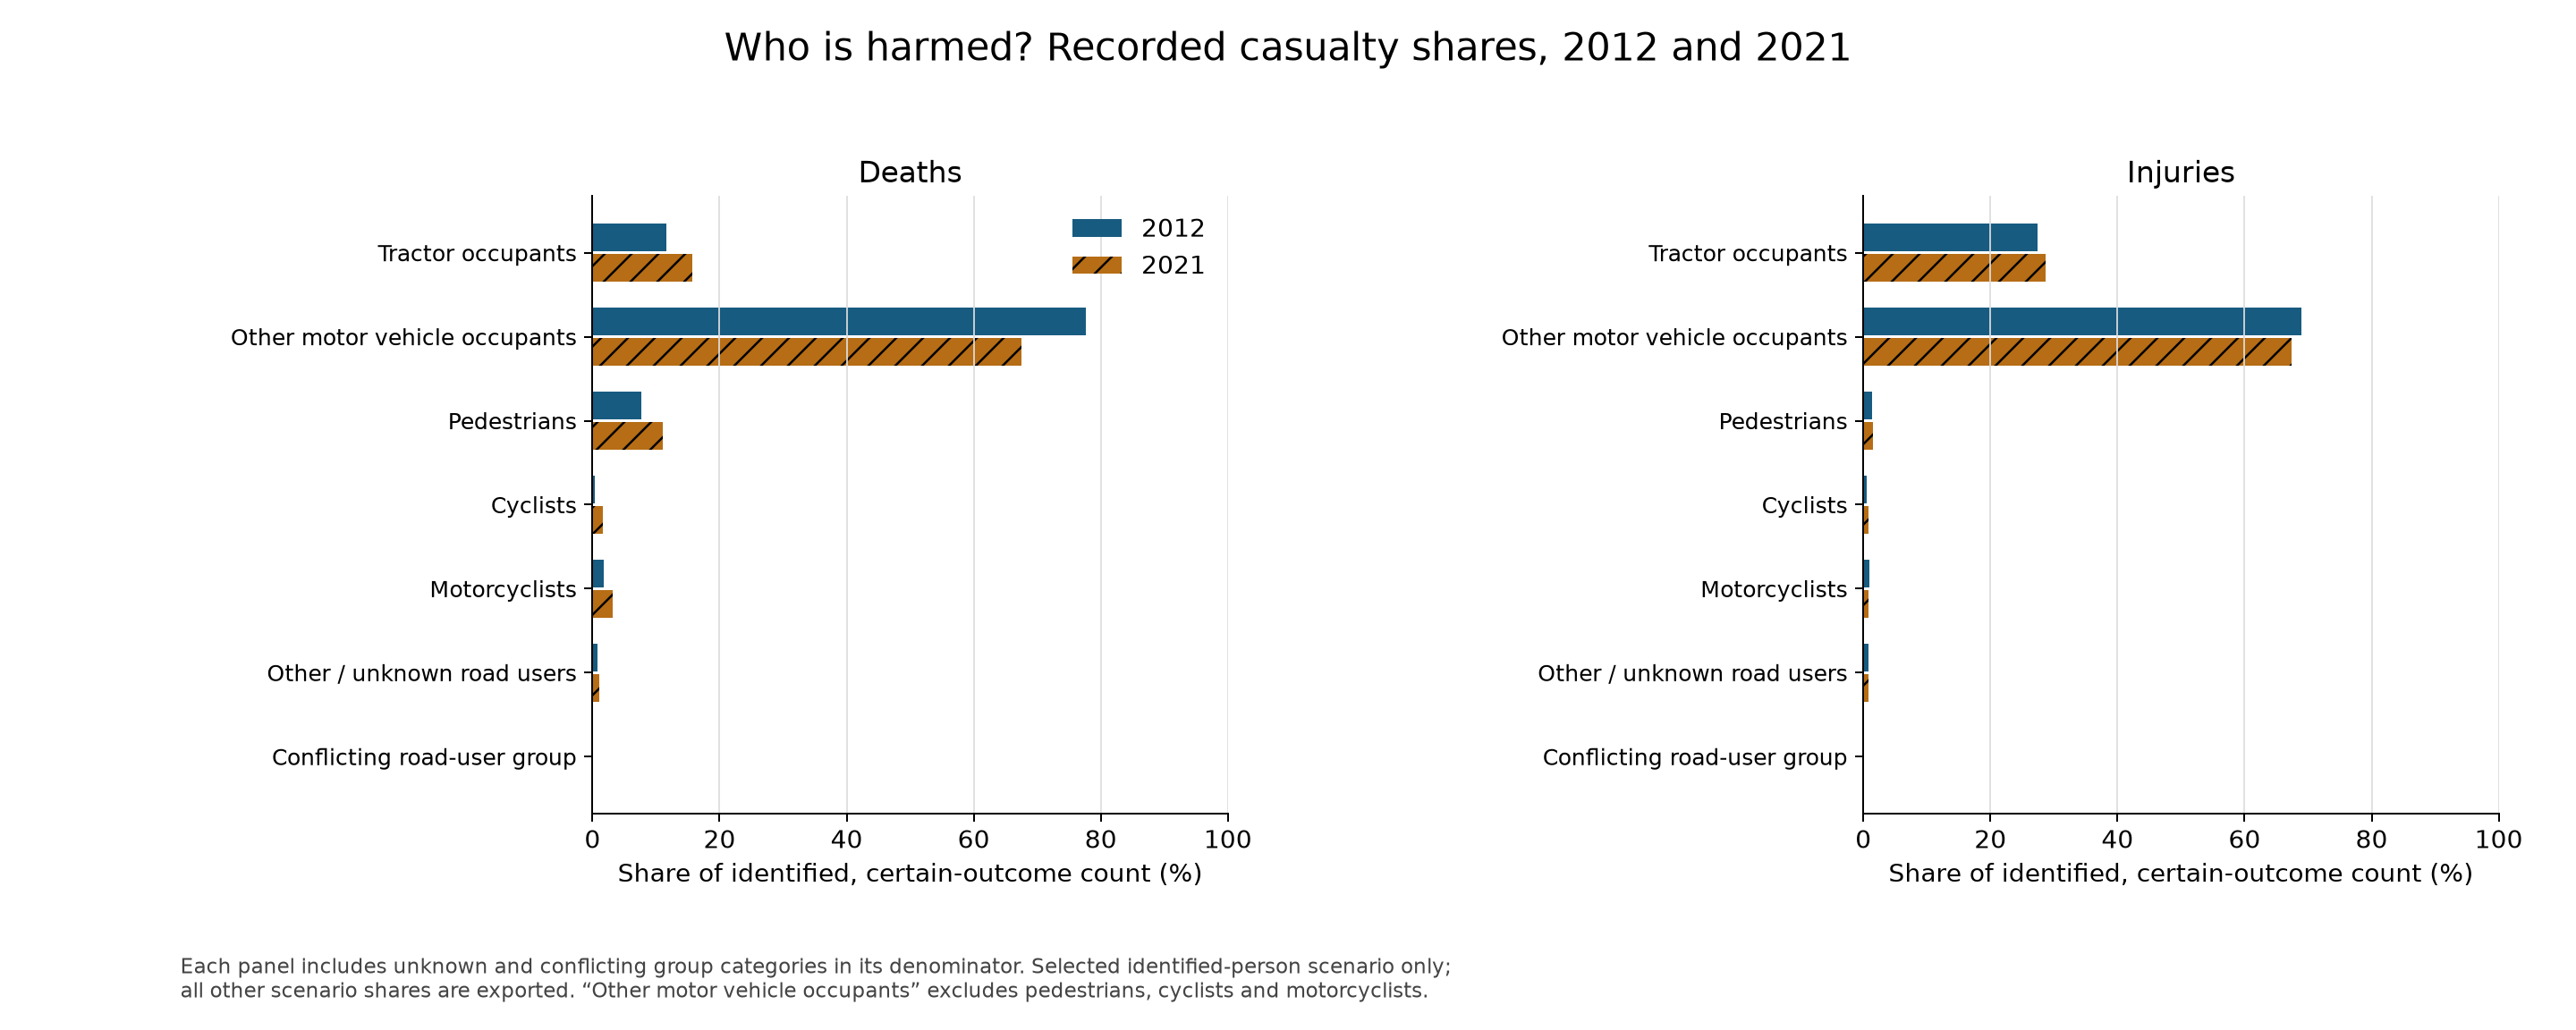

In [5]:
deaths2021=[r for r in grouped if r['year']==2021 and r['subset']=='observed']
assert sum(r['deaths_record_scenario_low'] for r in deaths2021)==191
other=next(r for r in deaths2021 if r['road_user_group']=='other_motor_vehicle_occupant')
assert other['deaths_record_scenario_low']==129
assert abs(100*129/191-67.5392670157)<1e-8
show_table(deaths2021,['road_user_group','deaths_record_scenario_low','deaths_record_scenario_high','injuries_record_scenario_low','injuries_record_scenario_high'])
display(Image(filename=str(out/'harm_shares.png')))

In 2021 other motor vehicle occupants represent 67.54% of recorded deaths, tractor occupants 15.71%, and pedestrians/cyclists/motorcyclists together 15.71%; other/unknown road users account for 1.05%. Rounded shares may not sum to exactly 100%.

Tractor occupant deaths changed from 27 to 30 across the two endpoints, while other motor vehicle occupant deaths changed from 181 to 129. Small subgroup counts fluctuate; this does not establish a difference in exposure-adjusted risk.

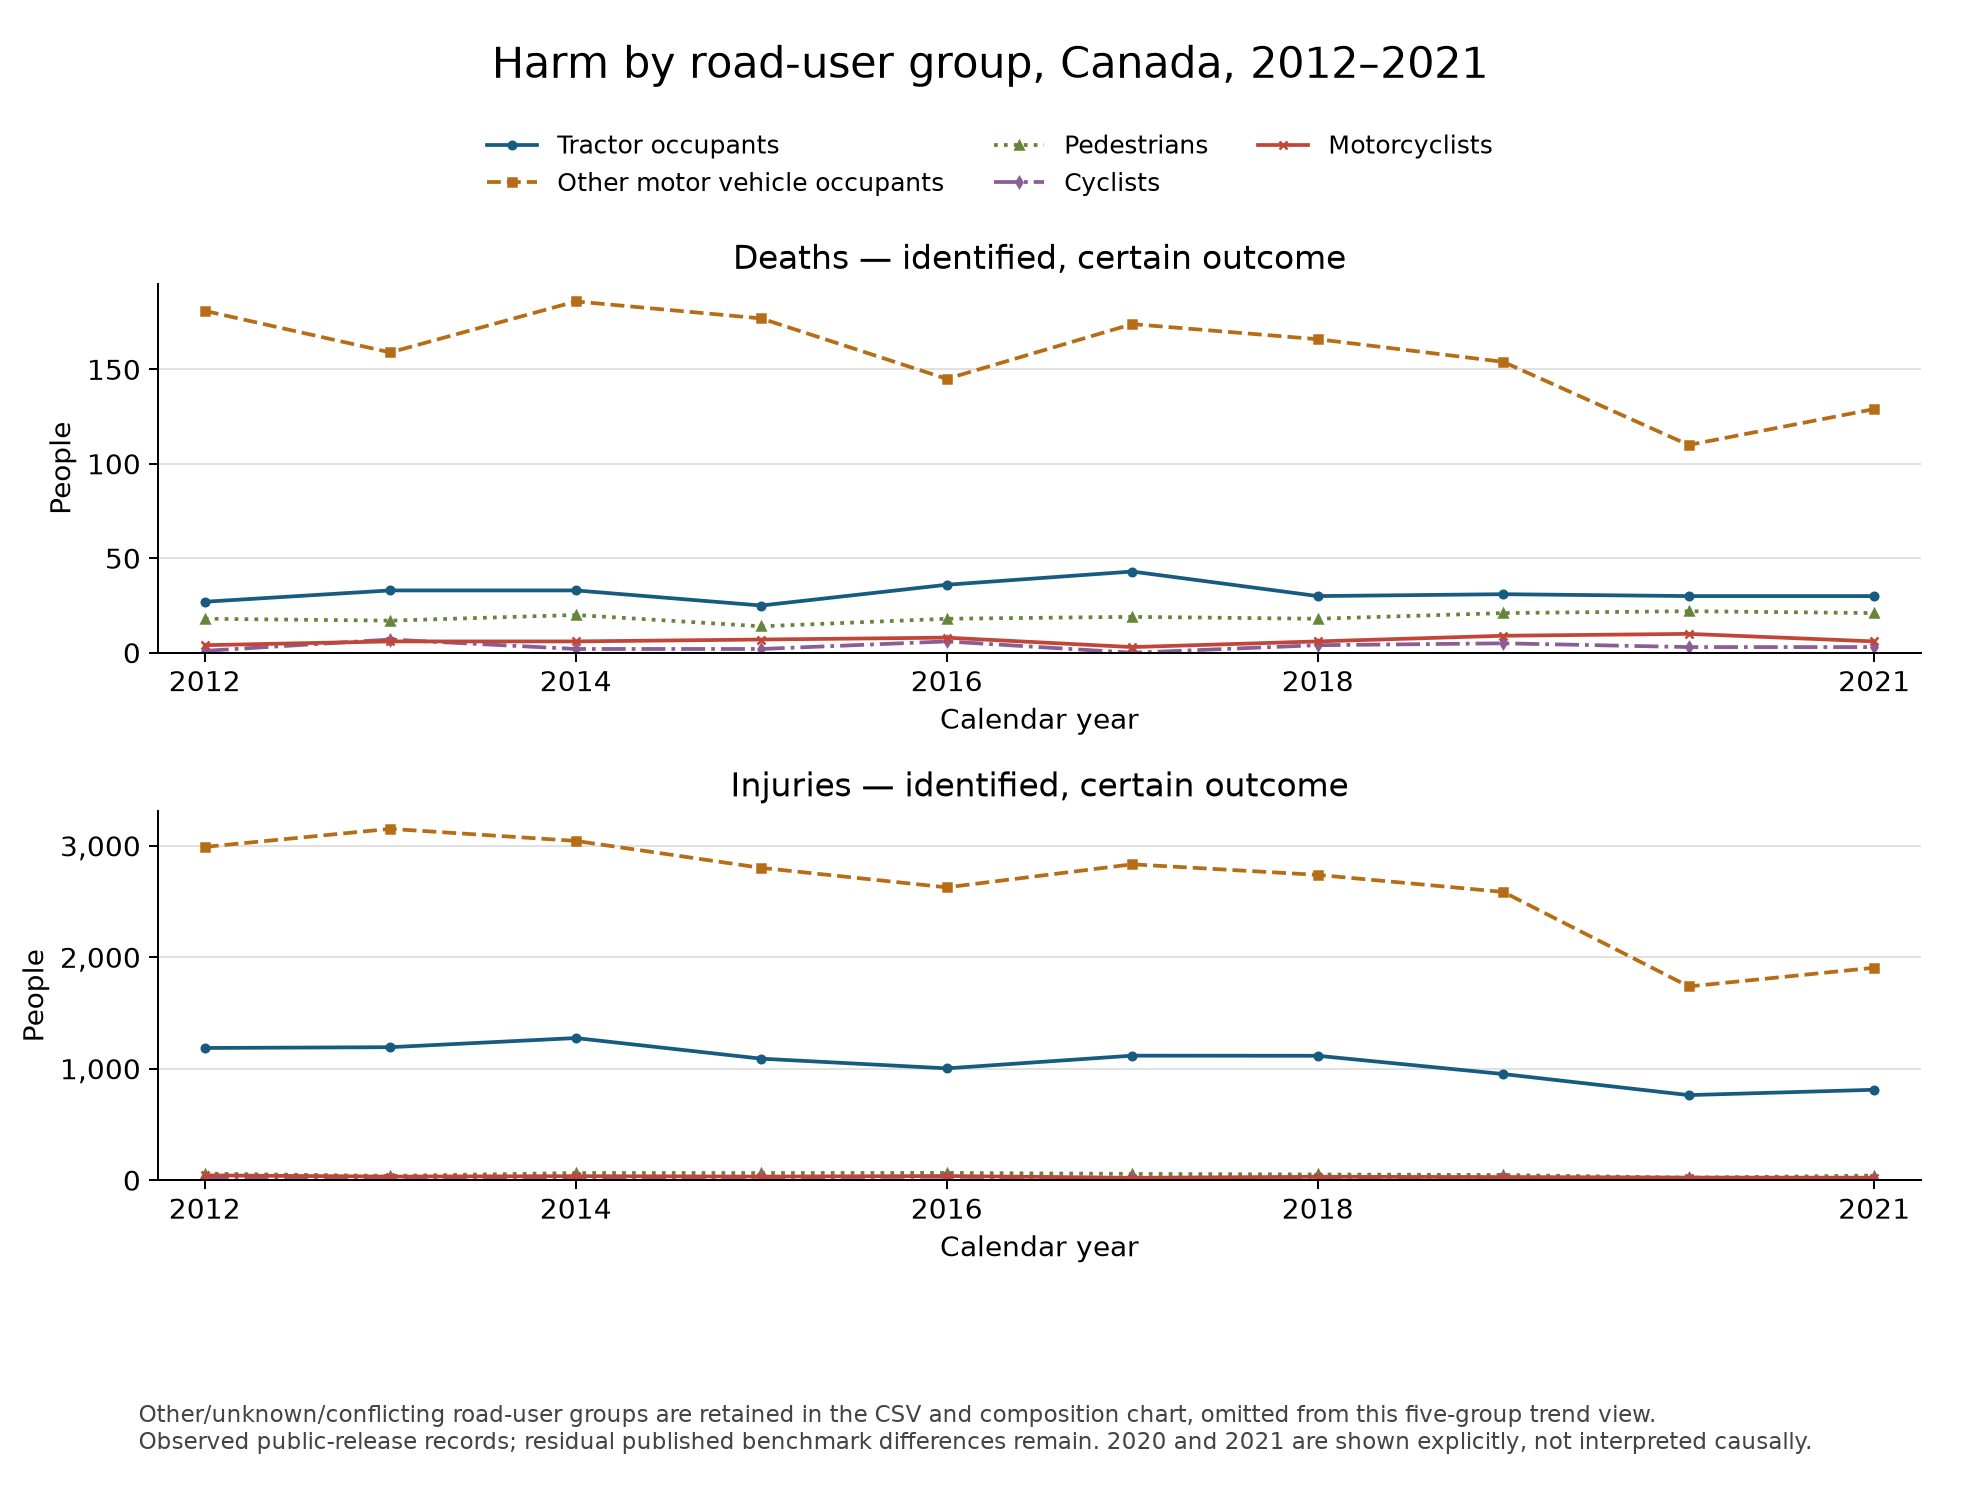

In [6]:
display(Image(filename=str(out/'group_harm_trends.png')))

### Endpoint, 2019 and strict-event sensitivities
Changes are computed separately in each coherent record scenario. Pooled means divide summed counts by included years. No fitted model or statistical significance is claimed.

In [7]:
with (out/'period_changes.csv').open() as stream: changes=list(csv.DictReader(stream))
selected=[r for r in changes if r['subset']=='observed' and r['road_user_group']=='all' and r['record_scenario']=='low']
for row in selected:
    assert abs(float(row['pct_change'])-100*(int(row['end_count'])/int(row['start_count'])-1))<1e-10
show_table(selected,['start_year','end_year','measure','start_count','end_count','pct_change'])
with (out/'strict_event_sensitivity.csv').open() as stream:sensitivity=list(csv.DictReader(stream))
show_table([r for r in sensitivity if r['year'] in ('2012','2016','2019','2020','2021')],['year','deaths_record_scenario_low_excluded','deaths_record_scenario_high_excluded','injuries_record_scenario_low_excluded','injuries_record_scenario_high_excluded'])

start_year,end_year,measure,start_count,end_count,pct_change
2012,2021,deaths,233,191,-18.02575107296137
2012,2021,injuries,4337,2828,-34.793636154023524
2012,2019,deaths,233,222,-4.72103004291845
2012,2019,injuries,4337,3665,-15.494581507954807
2016,2021,deaths,217,191,-11.981566820276502
2016,2021,injuries,3794,2828,-25.461254612546124
2016,2019,deaths,217,222,2.304147465437789
2016,2019,injuries,3794,3665,-3.4001054296257216
2019,2020,deaths,222,179,-19.369369369369373
2019,2020,injuries,3665,2599,-29.08594815825375


year,deaths_record_scenario_low_excluded,deaths_record_scenario_high_excluded,injuries_record_scenario_low_excluded,injuries_record_scenario_high_excluded
2012,0,0,0,0
2016,0,0,0,0
2019,0,0,0,0
2020,2,4,11,36
2021,0,0,7,22


### Harm per reported casualty collision
This links the person counts to the previously validated event counts. Deaths per 100 casualty collisions is different from fatal collision share and from risk per kilometre. Property-damage-only events are outside this dataset.

In [8]:
with (out/'harm_per_collision.csv').open() as stream: event_harm=list(csv.DictReader(stream))
show_table([r for r in event_harm if r['subset']=='observed' and r['year'] in ('2012','2016','2019','2020','2021')],['year','casualty_collisions','deaths_per_100_casualty_collisions_low','deaths_per_100_casualty_collisions_high','injuries_per_100_casualty_collisions_low','injuries_per_100_casualty_collisions_high'])
connection.close()

year,casualty_collisions,deaths_per_100_casualty_collisions_low,deaths_per_100_casualty_collisions_high,injuries_per_100_casualty_collisions_low,injuries_per_100_casualty_collisions_high
2012,3300,7.0606060606060606,7.0606060606060606,131.42424242424244,131.42424242424244
2016,3010,7.209302325581396,7.209302325581396,126.04651162790698,126.11295681063123
2019,2775,8.0,8.0,132.07207207207207,132.1081081081081
2020,2122,8.435438265786994,8.529688972667294,122.47879359095194,123.70405278039586
2021,2276,8.391915641476274,8.391915641476274,124.2530755711775,124.95606326889279


### External occupant benchmark remains partial
The classified tractor-occupant count is 30 deaths and 812 injuries in 2021, versus 29 and 806 published in Transport Canada’s report to Parliament; the 2021 traffic collision statistics report 28 and 806. These distinct published values are kept separate. Position 98/NN and unknown road-user assignment may explain some differences arithmetically, but this **classification hypothesis is unproven**, does not explain all benchmarks, and is not used to drop people. This comparison is occupant-only and cannot validate all-person casualties. Exact sources and source-specific rows are retained below.

In [9]:
with (out/'occupant_benchmark_comparison.csv').open() as stream: benchmark=list(csv.DictReader(stream))
show_table([r for r in benchmark if r['subset']=='observed'],['source_id','year','measure','count','classified_record_scenario_low','classified_record_scenario_high','low_minus_published'])
assert summary['status']=='record-resolution scenarios, not reconciled national person totals'
print('All person aggregate and arithmetic checks passed; external reconciliation remains partial.')

source_id,year,measure,count,classified_record_scenario_low,classified_record_scenario_high,low_minus_published
tc_2021_parliament_table12,2017,fatalities,43,43,43,0
tc_2021_parliament_table12,2017,nonfatal_injuries,1118,1118,1118,0
tc_2021_parliament_table12,2018,fatalities,30,30,30,0
tc_2021_parliament_table12,2018,nonfatal_injuries,1111,1117,1117,6
tc_2021_parliament_table12,2019,fatalities,30,31,31,1
tc_2021_parliament_table12,2019,nonfatal_injuries,948,953,953,5
tc_2021_parliament_table12,2020,fatalities,30,30,30,0
tc_2021_parliament_table12,2020,nonfatal_injuries,758,764,764,6
tc_2021_parliament_table12,2021,fatalities,29,30,30,1
tc_2021_parliament_table12,2021,nonfatal_injuries,806,812,812,6


All person aggregate and arithmetic checks passed; external reconciliation remains partial.


## Takeaways
Fewer recorded tractor casualty collisions coincided with fewer recorded deaths and injuries between 2012 and 2021, while deaths fell less than collision counts. Other motor vehicle occupants bear most recorded harm. Changes differ across groups, so an overall decline should not be treated as equal improvement for everyone.

The validated source-version update substantially reduced the 2019 event discrepancy, leaving two injury collisions below the published benchmark. This person analysis preserves that residual and partial occupant benchmark differences. No records for 2022–2025 have been added. Unknown identities, coded outcome conflicts, unknown/not-applicable severity, road-user ambiguity and strict-event sensitivities remain visible in the CSVs and validation outputs. Weather/configuration/time questions can follow with these distinctions retained.

Full interpretation, annual tables, exact exports and methodological limitations are in `reports/casualties/findings.md`.